In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import copy
import math


def showpic(image, text):
    plt.imshow(image, cmap='gray')
    plt.title(text)
    plt.show()

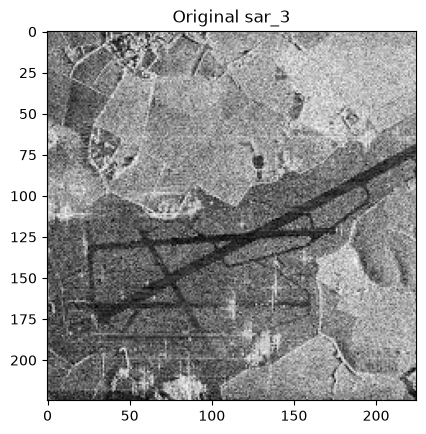

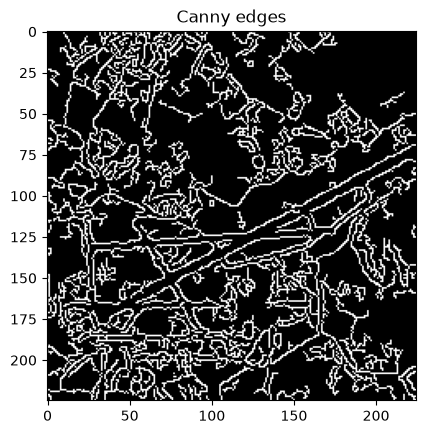

Longest line: (np.int64(13), np.int64(180), np.int64(223), np.int64(69))
Length: 237.5 px


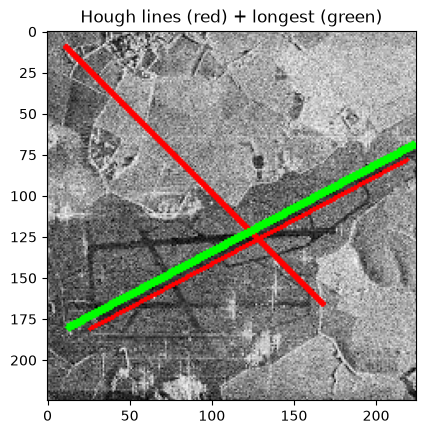

In [2]:
image = cv2.imread('source/sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
showpic(image_gray, 'Original sar_3')

blurred = cv2.GaussianBlur(image_gray, (5, 5), 0)
edges = cv2.Canny(blurred, 50, 150, apertureSize=3)
showpic(edges, 'Canny edges')

lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=100, minLineLength=80, maxLineGap=20)

image_lines = copy.deepcopy(image)
longest_line = None
max_len = 0

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = np.ravel(line)[:4].astype(int)
        cv2.line(image_lines, (x1, y1), (x2, y2), (0, 0, 255), 2)

        length = math.hypot(x2 - x1, y2 - y1)
        if length > max_len:
            max_len = length
            longest_line = (x1, y1, x2, y2)

    if longest_line is not None:
        x1, y1, x2, y2 = longest_line
        cv2.line(image_lines, (x1, y1), (x2, y2), (0, 255, 0), 3)
        print(f"Longest line: {longest_line}")
        print(f"Length: {max_len:.1f} px")

showpic(cv2.cvtColor(image_lines, cv2.COLOR_BGR2RGB), 'Hough lines (red) + longest (green)')

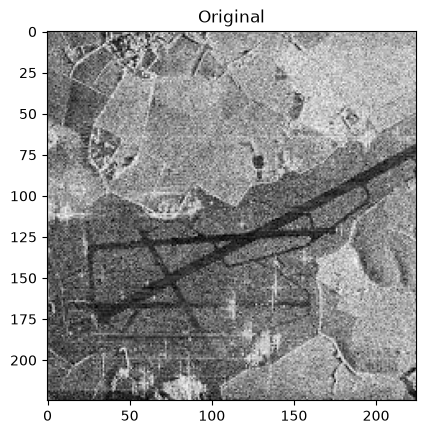

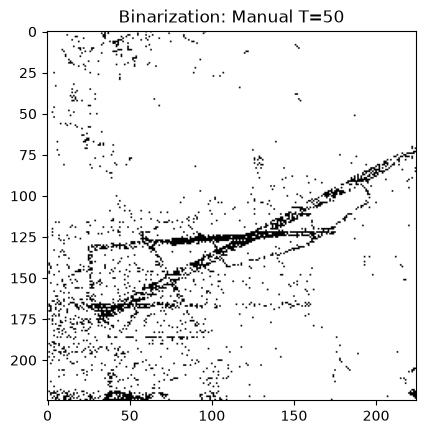

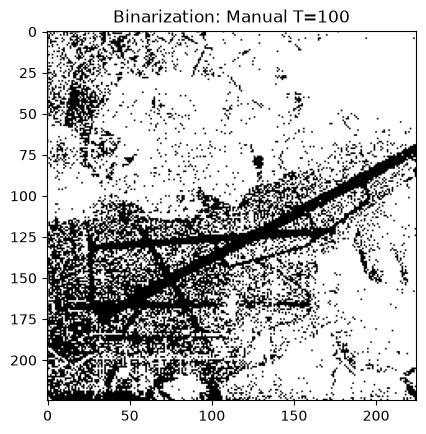

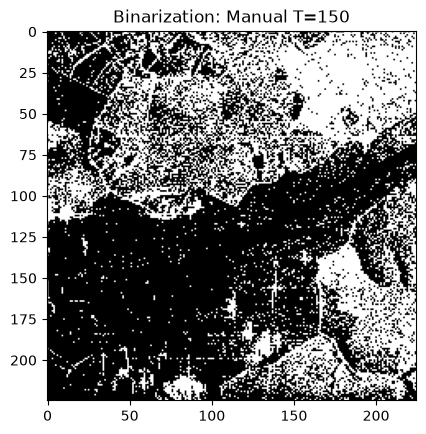

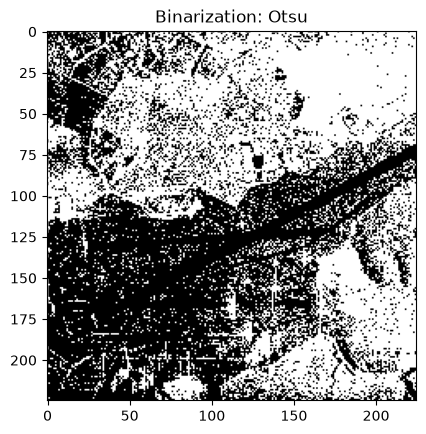

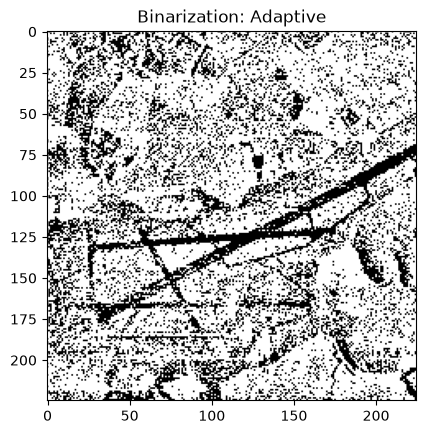

[Manual T=50] top-5 areas: [18637, 3208, 158, 97, 15]


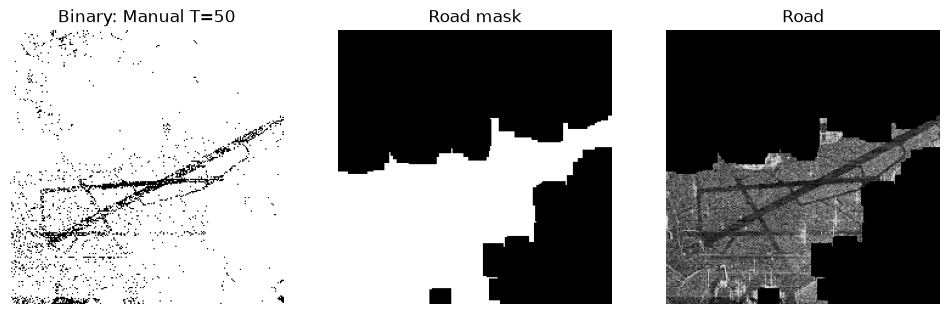

[Manual T=100] top-5 areas: [45381, 4, 0]


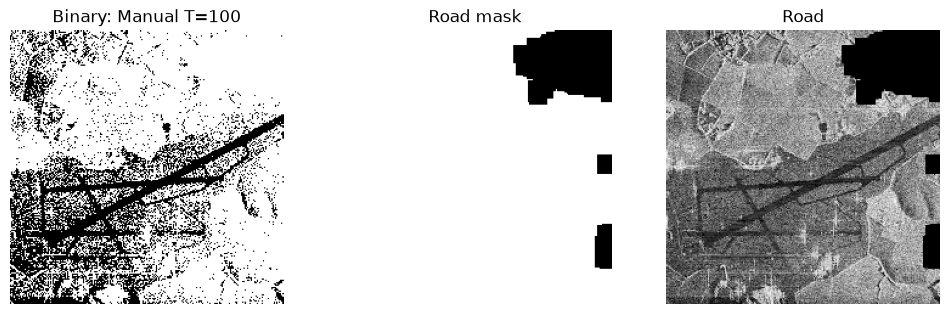

[Manual T=150] top-5 areas: [50176]


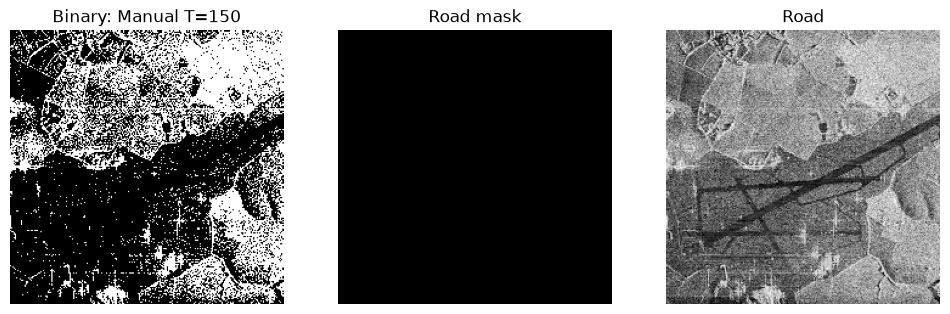

[Otsu] top-5 areas: [49925]


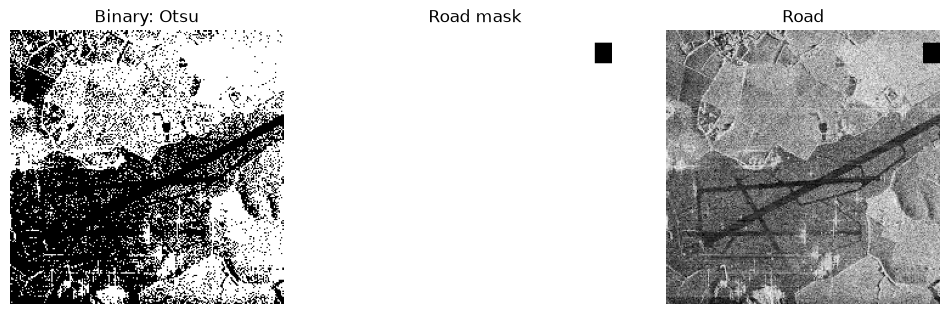

[Adaptive] top-5 areas: [50176]


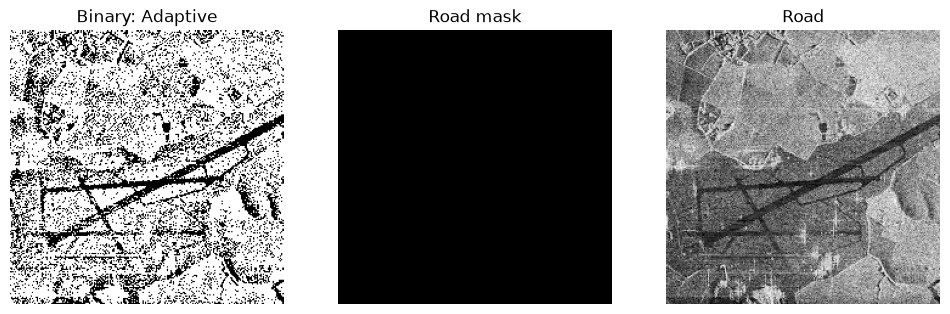

In [3]:
_, bin_manual_50 = cv2.threshold(image_gray, 50, 255, cv2.THRESH_BINARY)
_, bin_manual_100 = cv2.threshold(image_gray, 100, 255, cv2.THRESH_BINARY)
_, bin_manual_150 = cv2.threshold(image_gray, 150, 255, cv2.THRESH_BINARY)

_, bin_otsu = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

bin_adaptive = cv2.adaptiveThreshold(image_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 71, 21)

binarizations = {
    "Manual T=50": bin_manual_50,
    "Manual T=100": bin_manual_100,
    "Manual T=150": bin_manual_150,
    "Otsu": bin_otsu,
    "Adaptive": bin_adaptive
}

showpic(image_gray, 'Original')
for name, img in binarizations.items():
    showpic(img, f"Binarization: {name}")

kernel = np.ones((15, 15), np.uint8)

for name, binary in binarizations.items():
    binary_inv = cv2.bitwise_not(binary)

    closed = cv2.morphologyEx(binary_inv, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if not contours:
        print(f"[{name}] no contours")
        continue

    areas = sorted([cv2.contourArea(c) for c in contours], reverse=True)
    print(f"[{name}] top-5 areas: {[int(a) for a in areas[:5]]}")

    mask = np.zeros_like(binary)
    largest = max(contours, key=cv2.contourArea)
    cv2.drawContours(mask, [largest], -1, 255, thickness=cv2.FILLED)

    road = cv2.bitwise_and(image, image, mask=mask)

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1); plt.imshow(binary, cmap='gray')
    plt.title(f'Binary: {name}'); plt.axis('off')
    plt.subplot(1, 3, 2); plt.imshow(mask, cmap='gray')
    plt.title('Road mask'); plt.axis('off')
    plt.subplot(1, 3, 3); plt.imshow(cv2.cvtColor(road, cv2.COLOR_BGR2RGB))
    plt.title('Road'); plt.axis('off')
    plt.show()

In [4]:
print(f"{'Method':<15} | {'Top-5 areas':<40} | {'Road found?'}")
print('-' * 80)

for name, binary in binarizations.items():
    binary_inv = cv2.bitwise_not(binary)
    closed = cv2.morphologyEx(binary_inv, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    areas = sorted([int(cv2.contourArea(c)) for c in contours], reverse=True)
    top5 = areas[:5]

    valid = [a for a in areas if 500 < a < 10000]
    road = "YES" if valid else "no"

    print(f"{name:<15} | {str(top5):<40} | {road}")

Method          | Top-5 areas                              | Road found?
--------------------------------------------------------------------------------
Manual T=50     | [18637, 3208, 158, 97, 15]               | YES
Manual T=100    | [45381, 4, 0]                            | no
Manual T=150    | [50176]                                  | no
Otsu            | [49925]                                  | no
Adaptive        | [50176]                                  | no
